In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

# 1. Первичный анализ

In [40]:
FILE_PATH = 'Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)

data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [41]:
data.shape

(300, 9)

In [42]:
data.dtypes

age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

In [43]:
data.isna().sum()

age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [44]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [45]:
print(f'Maximum price: {data['price_azn'].max():.2f}')
print(f'Minimum price: {data['price_azn'].min():.2f}')

Maximum price: 51396.00
Minimum price: 3805.00


# 2. Визуализация

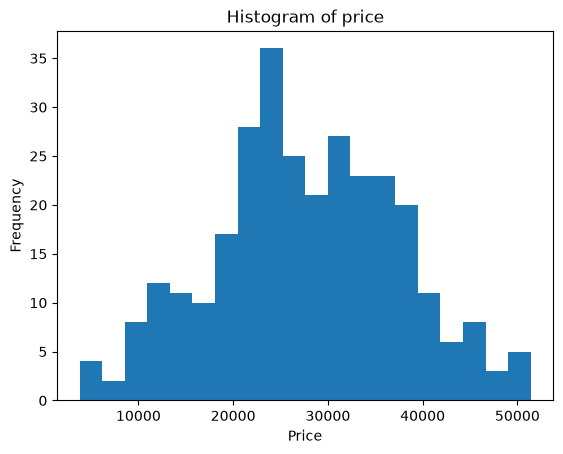

In [46]:
plt.figure()
plt.hist(data['price_azn'], bins=20)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of price')
plt.show()

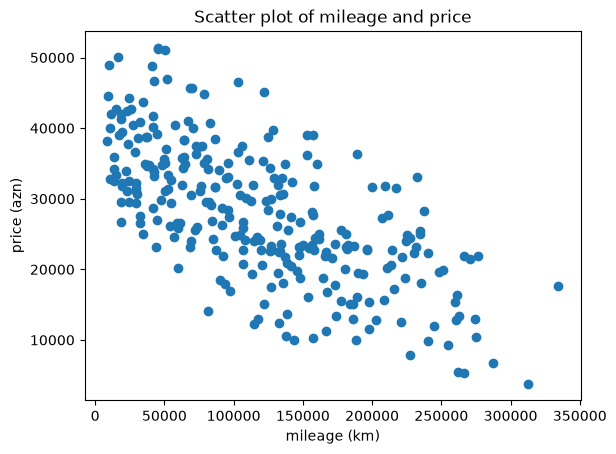

In [47]:
plt.figure()
plt.scatter(data['mileage_km'], data['price_azn'])
plt.xlabel('mileage (km)')
plt.ylabel('price (azn)')
plt.title('Scatter plot of mileage and price')
plt.show()

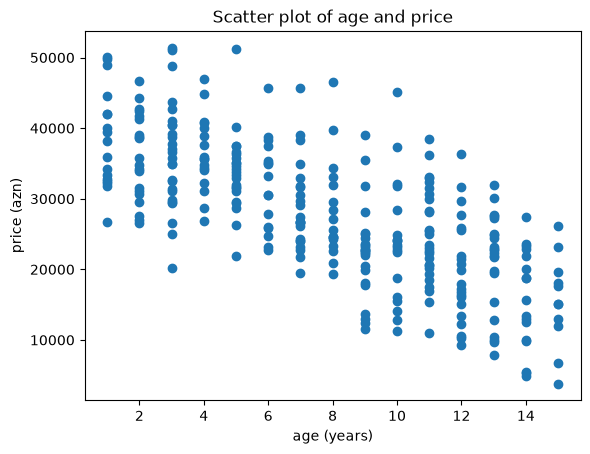

In [48]:
plt.figure()
plt.scatter(data['age_years'], data['price_azn'])
plt.xlabel('age (years)')
plt.ylabel('price (azn)')
plt.title('Scatter plot of age and price')
plt.show()

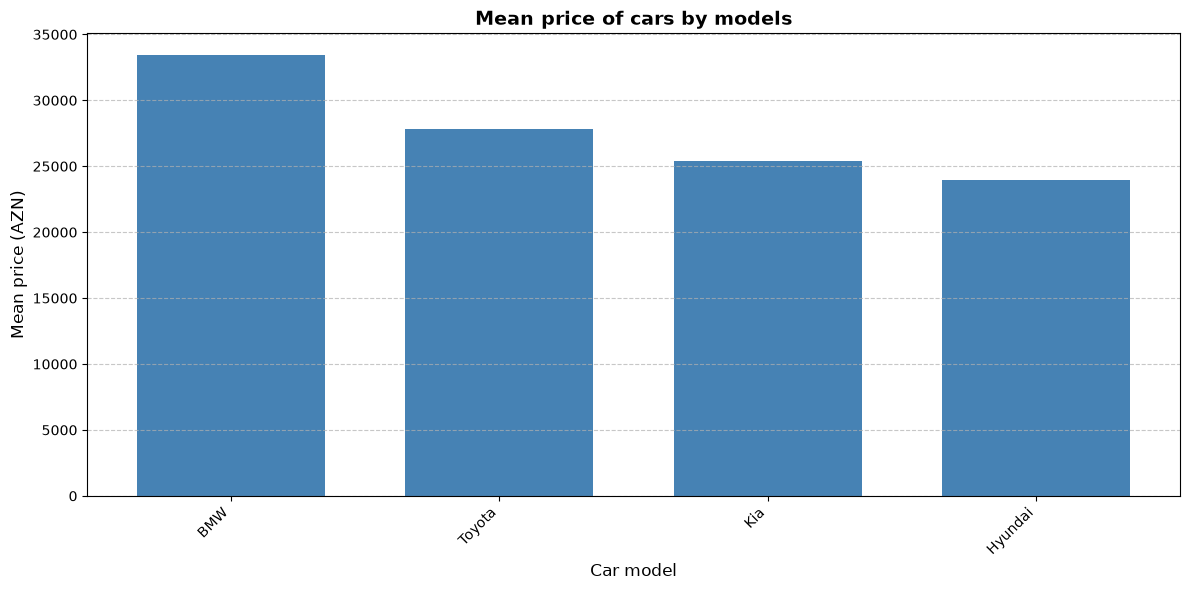

In [49]:
avg_price_by_brand = data.groupby('brand')['price_azn'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

bars = plt.bar(avg_price_by_brand.index, avg_price_by_brand.values, color='steelblue', width=0.7)

plt.title('Mean price of cars by models', fontsize=14, fontweight='bold')
plt.xlabel('Car model', fontsize=12)
plt.ylabel('Mean price (AZN)', fontsize=12)

plt.xticks(rotation=45, ha='right')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


# 3. Подготовка данных

In [50]:
X = data.drop(columns=['price_azn'])
y = data['price_azn']

X['mileage_per_year'] = X['mileage_km'] / (X['age_years'] + 1e-5)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category', 'bool', 'str']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

train_copy = X_train.copy()

brand_factorized, brand_uniques = pd.factorize(train_copy['brand'])
print("Результат factorize для brand (первые 5 значений):", brand_factorized[:5])

brand_ohe = pd.get_dummies(train_copy['brand'], prefix='brand')
print("\nРезультат One-Hot Encoding для brand (первые 5 строк):")
display(brand_ohe.head())

minmax_scaler = MinMaxScaler()
std_scaler = StandardScaler()

mileage_minmax = minmax_scaler.fit_transform(train_copy[['mileage_km']])
mileage_std = std_scaler.fit_transform(train_copy[['mileage_km']])

print(f"\nМинимум/Максимум до масштабирования: {train_copy['mileage_km'].min()} / {train_copy['mileage_km'].max()}")
print(f"MinMaxScaler (мин/макс после): {mileage_minmax.min():.2f} / {mileage_minmax.max():.2f}")
print(f"StandardScaler (среднее/ско после): {mileage_std.mean():.2f} / {mileage_std.std():.2f}")

Результат factorize для brand (первые 5 значений): [0 1 1 0 1]

Результат One-Hot Encoding для brand (первые 5 строк):


,brand_BMW,brand_Hyundai,brand_Kia,brand_Toyota
232,True,False,False,False
59,False,False,False,True
6,False,False,False,True
185,True,False,False,False
173,False,False,False,True



Минимум/Максимум до масштабирования: 8659.0 / 334305.0
MinMaxScaler (мин/макс после): nan / nan
StandardScaler (среднее/ско после): nan / nan


### Объяснение различий:
- Factorize кодирует категории целыми числами от 0 до N-1, навязывая искусственный порядок (ранги), которого у марок нет.
- One-Hot Encoding создает бинарные столбцы для каждого бренда, избегая ложного упорядочивания.
- MinMaxScaler сжимает данные в диапазон [0, 1], сохраняя исходные пропорции, но уязвим к выбросам.
- StandardScaler приводит признак к нулевому среднему и единичной дисперсии (нормальное распределение), что отлично подходит для линейных моделей.

# 4. Обучение и оценка

In [51]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2: {r2:.4f}")

MAE: 1414.62
MSE: 2886403.93
RMSE: 1698.94
R2: 0.9718


### Объяснение результатов:
- MAE показывает среднюю абсолютную ошибку в тех же единицах, что и целевая переменная (AZN).
- RMSE наказывает за крупные ошибки сильнее, так как возводит их в квадрат перед извлечением корня (также в AZN).
- R2 (коэффициент детерминации) показывает долю дисперсии целевой переменной, объясненную моделью (значение близкое к 1 говорит о хорошем качестве).

In [52]:
results_df = pd.DataFrame({
    'Реальная стоимость': y_test.values[:10],
    'Прогноз': y_pred[:10],
    'Абсолютная ошибка': np.abs(y_test.values[:10] - y_pred[:10])
})
display(results_df)

,Реальная стоимость,Прогноз,Абсолютная ошибка
0,34837,32094.813026,2742.186974
1,34946,33157.900338,1788.099662
2,32214,31152.652664,1061.347336
3,36190,35780.660997,409.339003
4,25000,23648.309242,1351.690758
5,26522,27360.102032,838.102032
6,22711,24210.682439,1499.682439
7,33061,32078.444057,982.555943
8,18479,19693.806842,1214.806842
9,25003,23457.436825,1545.563175


# 5. Проверка обучения

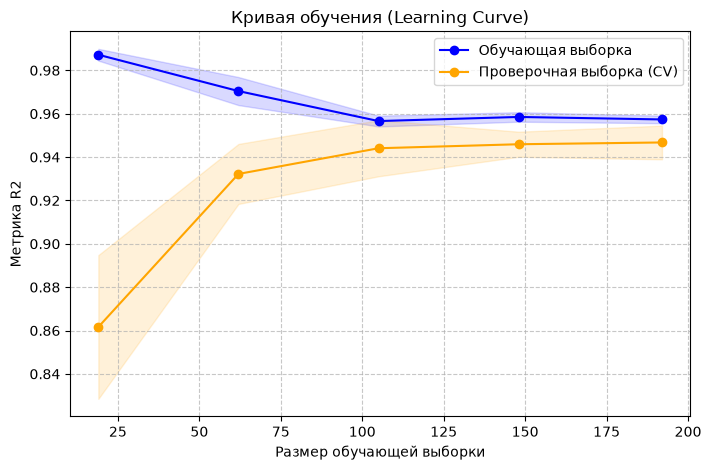

In [53]:
train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train, 
    train_sizes=np.linspace(0.1, 1.0, 5), 
    cv=5, 
    scoring='r2', 
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, label='Обучающая выборка', color='blue', marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.15)

plt.plot(train_sizes, val_mean, label='Проверочная выборка (CV)', color='orange', marker='o')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color='orange', alpha=0.15)

plt.title('Кривая обучения (Learning Curve)')
plt.xlabel('Размер обучающей выборки')
plt.ylabel('Метрика R2')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Объяснение:
- При увеличении размера обучающей выборки качество на валидации растет, а на обучении может немного падать до стабилизации. 
- Если графики сходятся на высоком уровне R2, модель стабильна и не имеет признаков сильного переобучения.

# 6. Прогноз для новых автомобилей

In [54]:
new_cars = pd.DataFrame({
    'age_years': [5, 10, 3],
    'mileage_km': [75000, 180000, 40000],
    'engine_l': [1.6, 2.0, 2.5],
    'power_hp': [110, 140, 170],
    'brand': ['Toyota', 'Hyundai', 'BMW'],
    'fuel_type': ['petrol', 'diesel', 'petrol'],
    'transmission': ['automatic', 'manual', 'automatic'],
    'accident_history': ['no', 'yes', 'no']
})

new_cars['mileage_per_year'] = new_cars['mileage_km'] / (new_cars['age_years'] + 1e-5)

new_predictions = model.predict(new_cars)

new_cars['predicted_price_azn'] = new_predictions
display(new_cars[['brand', 'age_years', 'mileage_km', 'predicted_price_azn']])

,brand,age_years,mileage_km,predicted_price_azn
0,Toyota,5,75000,31170.625859
1,Hyundai,10,180000,15912.006960
2,BMW,3,40000,48791.502614
